# Scorer Validation

Scorer の学習出力ディレクトリ（`config.yaml` + `checkpoints/*.ckpt`）を直接ロードし、
ranking モードでの rank_acc / AUROC / スコア分布・サンプル画像を確認する。

学習ログ末尾の `val/rank_acc`, `val/auroc`, `val/score_real`, `val/score_gen` と
ここでの計算結果が一致することを確認できる。

## Sec 0: 設定 + import

In [16]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchmetrics.classification import BinaryAUROC
from tqdm import tqdm

from real_fonts_vs_gen_fonts.datamodule import FontDataModule
from real_fonts_vs_gen_fonts.models.scorer_module import ScorerModule
from real_fonts_vs_gen_fonts.utils.config import load_config
from real_fonts_vs_gen_fonts.utils.torch_utils import get_device

# ---- 設定 ----
OUTPUT_DIR = Path("models/2026-06-10-13-04_scorer_H")
CKPT_NAME = "last.ckpt"   # checkpoints/ 配下のファイル名
USE_EMA = False            # EMA 平均重みを使うか
SPLIT = "train"             # "train" | "val" | "test"
N_SAMPLE_IMAGES = 32        # 高/低スコアサンプル表示数

## Sec 1: チェックポイント・データロード

In [17]:
device = get_device()
cfg = load_config(OUTPUT_DIR / "config.yaml")
data_cfg = cfg["data"]

assert cfg["model"]["ranking"], "このノートブックは mode='ranking' の学習出力を想定しています"

ckpt_path = OUTPUT_DIR / "checkpoints" / CKPT_NAME
scorer_module: ScorerModule = ScorerModule.load_from_checkpoint(ckpt_path, map_location="cpu")
scorer_module.eval().to(device)

dm = FontDataModule(
    real_data_dir=data_cfg["real_data_dir"],
    gen_data_dir=data_cfg["gen_data_dir"],
    mode=data_cfg["mode"],
    pair_sampling=data_cfg.get("pair_sampling", "same_char"),
    charset=data_cfg["charset"],
    image_size=data_cfg["image_size"],
    batch_size=data_cfg["batch_size"],
    val_split=data_cfg["val_split"],
    test_split=data_cfg["test_split"],
    num_workers=data_cfg.get("num_workers", 4),
    seed=data_cfg["seed"],
    binarize_threshold=data_cfg.get("binarize_threshold"),
    split_file=data_cfg.get("split_file"),
    gen_split_file=data_cfg.get("gen_split_file"),
    aug_scale=data_cfg.get("aug_scale"),
    aug_translate=data_cfg.get("aug_translate"),
)
dm.setup(None)

loader = {
    "train": dm.train_dataloader,
    "val": dm.val_dataloader,
    "test": dm.test_dataloader,
}[SPLIT]()

print(f"checkpoint: {ckpt_path}")
print(f"split: {SPLIT}  ({len(loader.dataset)} samples)")

.venv/lib/python3.12/site-packages/lightning/fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


checkpoint: models/2026-06-10-13-04_scorer_H/checkpoints/last.ckpt
split: train  (2656 samples)


## Sec 2: メトリクス計算（rank_acc, AUROC, スコア分布）

In [18]:
@torch.no_grad()
def collect_scores(loader, scorer_module, device):
    scorer = scorer_module.scorer
    real_imgs, gen_imgs = [], []
    score_real_list, score_gen_list = [], []

    for batch in tqdm(loader, desc="scoring"):
        real_image = batch["real_image"].to(device)
        gen_image = batch["gen_image"].to(device)

        s_real = scorer(real_image)
        s_gen = scorer(gen_image)

        score_real_list.append(s_real.cpu())
        score_gen_list.append(s_gen.cpu())
        real_imgs.append(batch["real_image"].cpu())
        gen_imgs.append(batch["gen_image"].cpu())

    return (
        torch.cat(score_real_list),
        torch.cat(score_gen_list),
        torch.cat(real_imgs),
        torch.cat(gen_imgs),
    )


if USE_EMA:
    with scorer_module._ema.average_parameters():
        score_real, score_gen, real_images, gen_images = collect_scores(loader, scorer_module, device)
else:
    score_real, score_gen, real_images, gen_images = collect_scores(loader, scorer_module, device)

rank_acc = (score_real > score_gen).float().mean().item()

auroc_metric = BinaryAUROC()
scores = torch.cat([score_real, score_gen])
labels = torch.cat([torch.ones_like(score_real, dtype=torch.long), torch.zeros_like(score_gen, dtype=torch.long)])
auroc = auroc_metric(scores, labels).item()

print(f"split          : {SPLIT}")
print(f"use_ema         : {USE_EMA}")
print(f"rank_acc        : {rank_acc:.4f}")
print(f"auroc           : {auroc:.4f}")
print(f"score_real mean : {score_real.mean().item():.4f}  std: {score_real.std().item():.4f}")
print(f"score_gen  mean : {score_gen.mean().item():.4f}  std: {score_gen.std().item():.4f}")

scoring: 100%|██████████| 21/21 [00:00<00:00, 34.61it/s]

split          : train
use_ema         : False
rank_acc        : 0.8215
auroc           : 0.8215
score_real mean : 0.3338  std: 0.1485
score_gen  mean : 0.2083  std: 0.0682


## Sec 3: スコア分布のヒストグラム

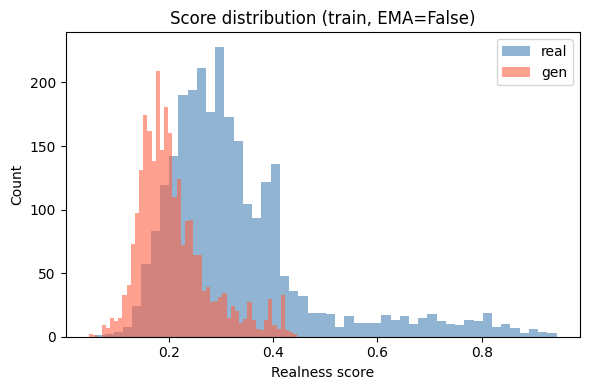

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(score_real.numpy(), bins=50, alpha=0.6, label="real", color="steelblue")
ax.hist(score_gen.numpy(), bins=50, alpha=0.6, label="gen", color="tomato")
ax.set_xlabel("Realness score")
ax.set_ylabel("Count")
ax.set_title(f"Score distribution ({SPLIT}, EMA={USE_EMA})")
ax.legend()
plt.tight_layout()
plt.show()

## Sec 4: サンプル画像グリッド（高スコア／低スコア）

- gen 画像のうち score が高い順（real と誤認しやすい）
- gen 画像のうち score が低い順
- real 画像のうち score が低い順（gen と誤認しやすい）
- real 画像のうち score が高い順

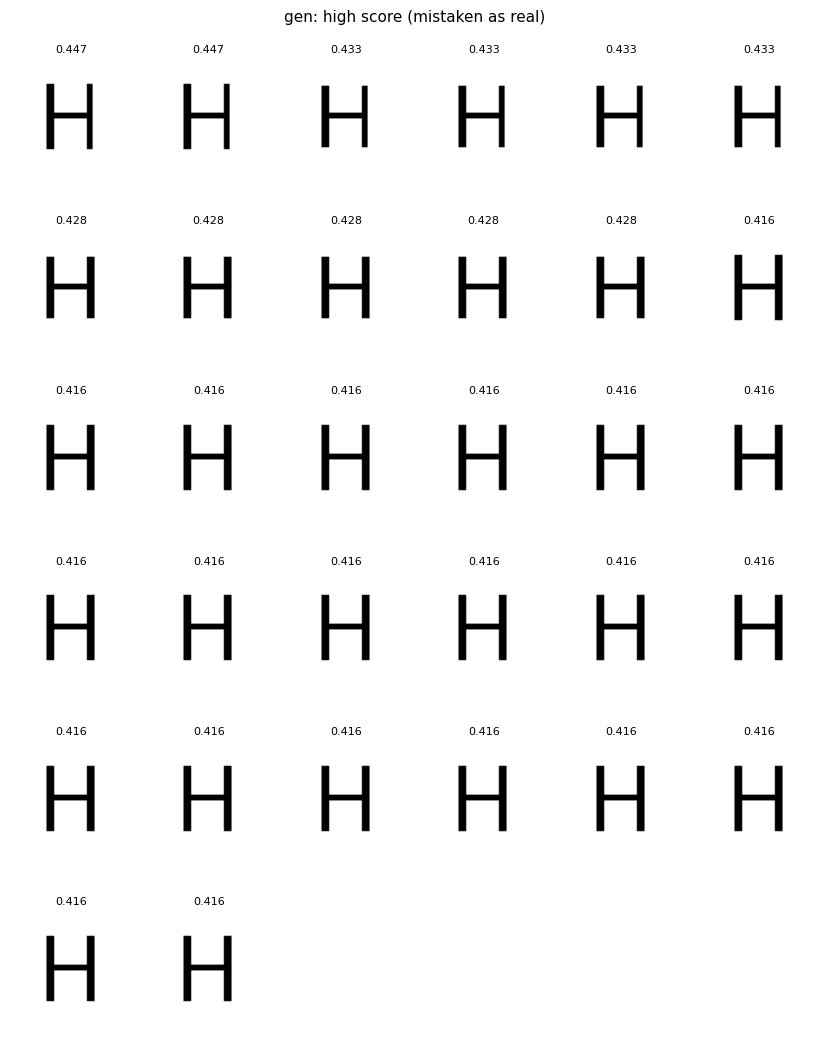

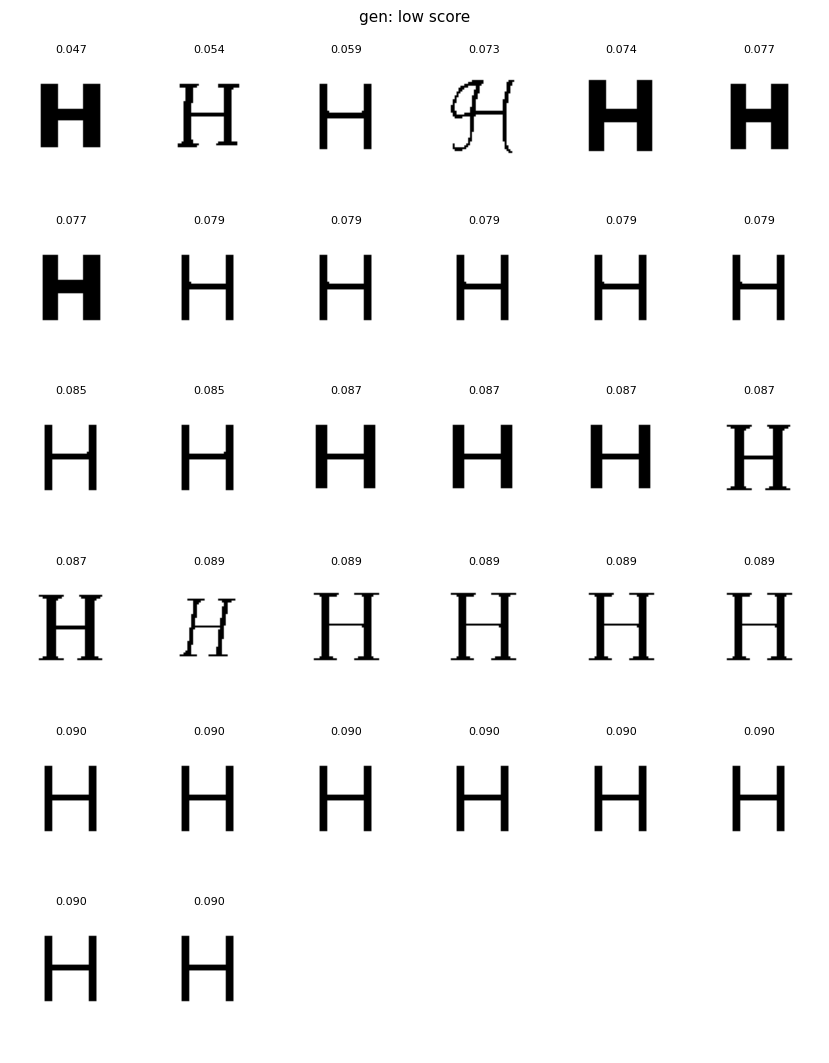

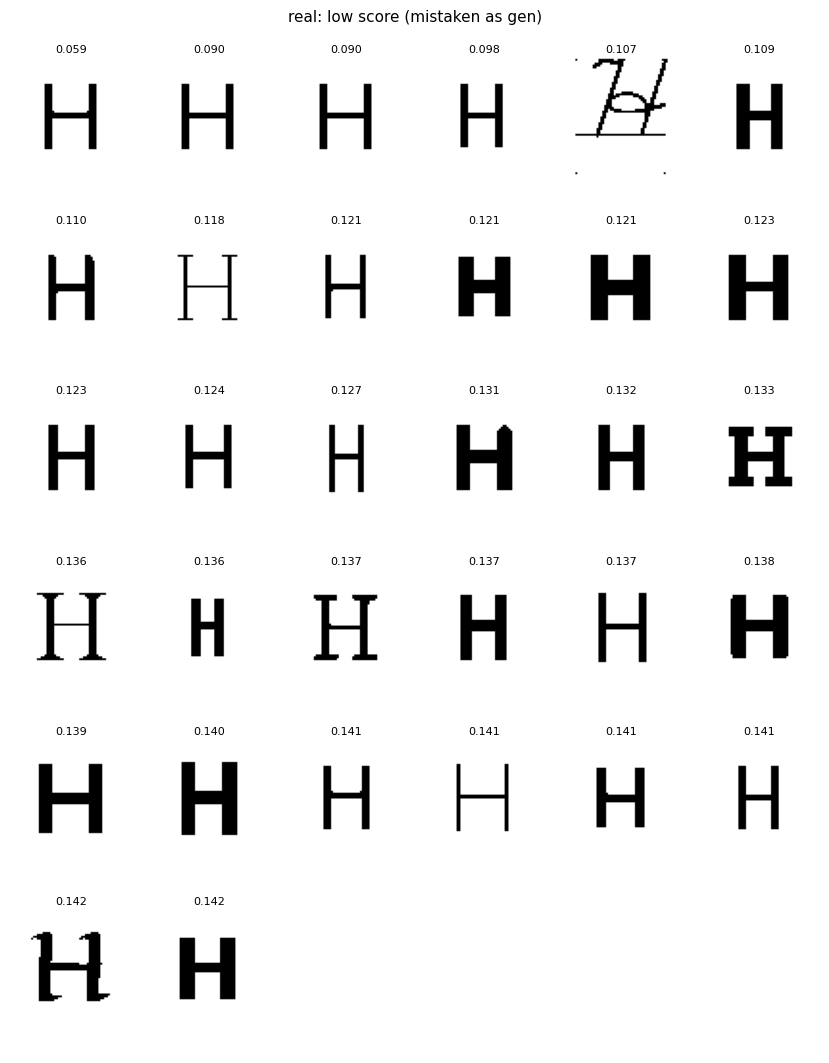

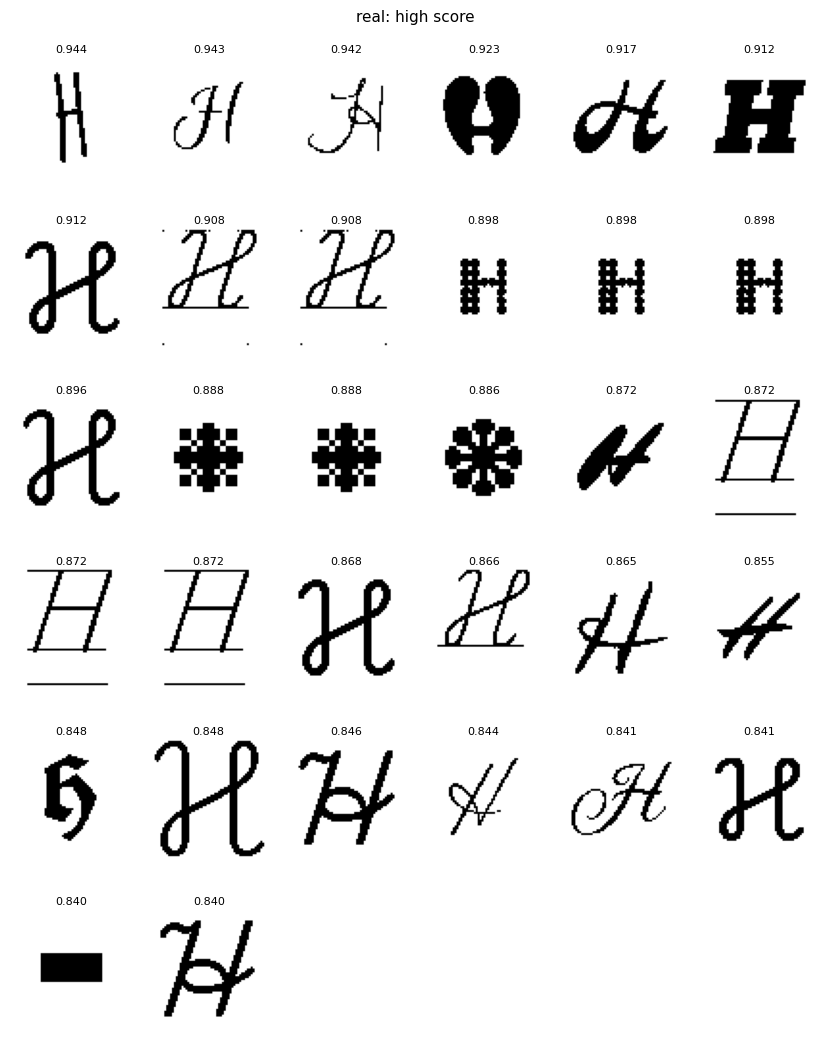

In [20]:
def show_image_grid(images: torch.Tensor, scores: torch.Tensor, title: str, n_cols: int | None = None, img_size: float = 1.4) -> None:
    """images: (N, C, H, W) in [0, 1]. scores: (N,) を各画像のタイトルに表示する。"""
    n = len(images)
    if n == 0:
        print(f"[SKIP] No images to show for '{title}'")
        return
    if n_cols is None:
        n_cols = math.ceil(math.sqrt(n))
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * img_size, n_rows * (img_size + 0.4)), squeeze=False)
    for idx in range(n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        ax = axes[r, c]
        ax.axis("off")
        if idx < n:
            img = images[idx].permute(1, 2, 0).numpy()
            if img.shape[2] == 1:
                img = img[:, :, 0]
            ax.imshow(np.clip(img, 0, 1), cmap="gray" if img.ndim == 2 else None)
            ax.set_title(f"{scores[idx].item():.3f}", fontsize=8, pad=2)

    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


n = N_SAMPLE_IMAGES

gen_high_idx = score_gen.argsort(descending=True)[:n]
show_image_grid(gen_images[gen_high_idx], score_gen[gen_high_idx], "gen: high score (mistaken as real)")

gen_low_idx = score_gen.argsort()[:n]
show_image_grid(gen_images[gen_low_idx], score_gen[gen_low_idx], "gen: low score")

real_low_idx = score_real.argsort()[:n]
show_image_grid(real_images[real_low_idx], score_real[real_low_idx], "real: low score (mistaken as gen)")

real_high_idx = score_real.argsort(descending=True)[:n]
show_image_grid(real_images[real_high_idx], score_real[real_high_idx], "real: high score")